# Лабораторна робота №2 “Baseline Classification Pipeline”

Мета: відтворити базовий життєвий цикл машинного навчання для задачі класифікації: підготувати дані, розділити їх на навчальну та валідаційну вибірки, навчити модель, оцінити її якість та сформувати прогноз для тестових даних.

ХІД РОБОТИ

Відтворимо базовий життєвий цикл машинного навчання для задачі класифікації

In [1]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score,confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

##### Завантажимо та підготуємо дані для навчання

In [2]:
train_data = pd.read_csv('lab2/application_train.csv')

In [3]:
train_data.shape

(307511, 122)

In [4]:
train_data.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


##### Відокремимо цільову змінну від ознак

In [5]:
target = train_data['TARGET']

In [6]:
target.head()

0    1
1    0
2    0
3    0
4    0
Name: TARGET, dtype: int64

In [7]:
train_dataset = train_data.drop(['TARGET', 'SK_ID_CURR'], axis=1)

In [8]:
train_dataset.head()

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
train_dataset.shape

(307511, 120)

Розділимо навчальні дані на навчальну та валідаційну вибірки (train-validation split)

In [10]:
validation_set = train_dataset.sample(frac=0.2, random_state=42)
print(validation_set.shape)

(61502, 120)


In [11]:
validation_set.head()

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
245895,Cash loans,M,Y,N,2,207000.0,465457.5,52641.0,418500.0,Unaccompanied,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,1.0
98194,Cash loans,F,Y,Y,0,247500.0,1281712.5,48946.5,1179000.0,Unaccompanied,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,3.0
36463,Cash loans,F,Y,N,0,202500.0,495000.0,39109.5,495000.0,Unaccompanied,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,3.0
249923,Cash loans,F,N,Y,0,247500.0,254700.0,24939.0,225000.0,Unaccompanied,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
158389,Cash loans,M,N,Y,0,112500.0,308133.0,15862.5,234000.0,Unaccompanied,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,4.0


In [12]:
features = train_dataset.drop(validation_set.index)
validation_target = target[validation_set.index]
train_target = target.drop(validation_set.index)

In [13]:
features.shape

(246009, 120)

Виконаємо базову обробку даних, необхідну для навчання моделі (видалення або заповнення пропущених значень, кодування категоріальних ознак тощо

In [14]:
features.isnull().sum().sort_values(ascending=False)

COMMONAREA_AVG              171930
COMMONAREA_MODE             171930
COMMONAREA_MEDI             171930
NONLIVINGAPARTMENTS_AVG     170869
NONLIVINGAPARTMENTS_MODE    170869
                             ...  
FLAG_DOCUMENT_16                 0
FLAG_DOCUMENT_15                 0
FLAG_DOCUMENT_14                 0
FLAG_DOCUMENT_20                 0
FLAG_DOCUMENT_21                 0
Length: 120, dtype: int64

In [15]:
sorted_features = features[features.columns[features.isnull().sum() < 116692 ]]
sorted_features.shape

(246009, 71)

In [16]:
print(sorted_features.isnull().sum().sort_values(ascending=False))

OCCUPATION_TYPE               77106
EXT_SOURCE_3                  48824
AMT_REQ_CREDIT_BUREAU_YEAR    33211
AMT_REQ_CREDIT_BUREAU_MON     33211
AMT_REQ_CREDIT_BUREAU_WEEK    33211
                              ...  
FLAG_DOCUMENT_16                  0
FLAG_DOCUMENT_15                  0
FLAG_DOCUMENT_14                  0
FLAG_DOCUMENT_20                  0
FLAG_DOCUMENT_21                  0
Length: 71, dtype: int64


In [17]:
col_to_fill = sorted_features[sorted_features.columns[sorted_features.isnull().sum() >= 1]]

In [18]:
print(col_to_fill.head())

   AMT_ANNUITY  AMT_GOODS_PRICE  NAME_TYPE_SUITE OCCUPATION_TYPE  \
1      35698.5        1129500.0           Family      Core staff   
3      29686.5         297000.0    Unaccompanied        Laborers   
4      21865.5         513000.0    Unaccompanied      Core staff   
5      27517.5         454500.0  Spouse, partner        Laborers   
7      42075.0        1530000.0    Unaccompanied        Managers   

   CNT_FAM_MEMBERS  EXT_SOURCE_2  EXT_SOURCE_3  OBS_30_CNT_SOCIAL_CIRCLE  \
1              2.0      0.622246           NaN                       1.0   
3              2.0      0.650442           NaN                       2.0   
4              1.0      0.322738           NaN                       0.0   
5              2.0      0.354225      0.621226                       0.0   
7              2.0      0.714279      0.540654                       2.0   

   DEF_30_CNT_SOCIAL_CIRCLE  OBS_60_CNT_SOCIAL_CIRCLE  \
1                       0.0                       1.0   
3                   

In [19]:
col_to_fill.select_dtypes(['str']).columns

Index(['NAME_TYPE_SUITE', 'OCCUPATION_TYPE'], dtype='str')

In [20]:
num_col_to_fill = col_to_fill.drop(["NAME_TYPE_SUITE", "OCCUPATION_TYPE"], axis=1).columns
print(num_col_to_fill)

Index(['AMT_ANNUITY', 'AMT_GOODS_PRICE', 'CNT_FAM_MEMBERS', 'EXT_SOURCE_2',
       'EXT_SOURCE_3', 'OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE',
       'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE',
       'DAYS_LAST_PHONE_CHANGE', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='str')


In [21]:
train_mean = sorted_features[num_col_to_fill].mean(skipna=True)

In [22]:
sorted_features[num_col_to_fill] = sorted_features[num_col_to_fill].fillna(train_mean)

In [23]:
sorted_features.isnull().sum().sort_values(ascending=False)

OCCUPATION_TYPE               77106
NAME_TYPE_SUITE                1046
NAME_CONTRACT_TYPE                0
FLAG_OWN_REALTY                   0
CNT_CHILDREN                      0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY         0
AMT_REQ_CREDIT_BUREAU_WEEK        0
AMT_REQ_CREDIT_BUREAU_MON         0
AMT_REQ_CREDIT_BUREAU_QRT         0
AMT_REQ_CREDIT_BUREAU_YEAR        0
Length: 71, dtype: int64

In [24]:
categ_col_to_fill = col_to_fill[["NAME_TYPE_SUITE", "OCCUPATION_TYPE"]].columns

In [25]:
NAME_TYPE_SUITE_mode = sorted_features['NAME_TYPE_SUITE'].mode()[0]

In [26]:
sorted_features['NAME_TYPE_SUITE'] = sorted_features['NAME_TYPE_SUITE'].fillna(NAME_TYPE_SUITE_mode)


In [27]:
OCCUPATION_TYPE_mode = sorted_features['OCCUPATION_TYPE'].mode()[0]

In [28]:
sorted_features['OCCUPATION_TYPE'] = sorted_features['OCCUPATION_TYPE'].fillna(OCCUPATION_TYPE_mode)


In [29]:
sorted_features.isnull().sum().sort_values(ascending=False)

NAME_CONTRACT_TYPE            0
CODE_GENDER                   0
FLAG_OWN_CAR                  0
FLAG_OWN_REALTY               0
CNT_CHILDREN                  0
                             ..
AMT_REQ_CREDIT_BUREAU_DAY     0
AMT_REQ_CREDIT_BUREAU_WEEK    0
AMT_REQ_CREDIT_BUREAU_MON     0
AMT_REQ_CREDIT_BUREAU_QRT     0
AMT_REQ_CREDIT_BUREAU_YEAR    0
Length: 71, dtype: int64

In [30]:
sorted_features.shape

(246009, 71)

In [31]:
categorical_columns = sorted_features.select_dtypes(include=['str']).columns
encoder = OneHotEncoder(sparse_output=False)
encoded_data = encoder.fit_transform(sorted_features[categorical_columns])
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(categorical_columns),
    index = sorted_features.index
)
final_df = pd.concat(
    [sorted_features.drop(columns=categorical_columns), encoded_df],
    axis=1
)
print("\nOne-Hot Encoded Data:")
print(final_df)


One-Hot Encoded Data:
        CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
1                  0          270000.0   1293502.5      35698.5   
3                  0          135000.0    312682.5      29686.5   
4                  0          121500.0    513000.0      21865.5   
5                  0           99000.0    490495.5      27517.5   
7                  0          360000.0   1530000.0      42075.0   
...              ...               ...         ...          ...   
307506             0          157500.0    254700.0      27558.0   
307507             0           72000.0    269550.0      12001.5   
307508             0          153000.0    677664.0      29979.0   
307509             0          171000.0    370107.0      20205.0   
307510             0          157500.0    675000.0      49117.5   

        AMT_GOODS_PRICE  REGION_POPULATION_RELATIVE  DAYS_BIRTH  \
1             1129500.0                    0.003541      -16765   
3              297000.0               

In [32]:
print(train_target.shape)

(246009,)


Навчимо дерево рішень (Decision Tree Classifier) із параметрами за замовчуванням


In [33]:
clf = DecisionTreeClassifier(random_state=1)
clf.fit(final_df, train_target)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

Оцінимо якість моделі на валідаційній вибірці за метрикою ROC-AUC

In [34]:
validation_set.isnull().sum().sort_values(ascending=False)

COMMONAREA_AVG              42935
COMMONAREA_MODE             42935
COMMONAREA_MEDI             42935
NONLIVINGAPARTMENTS_AVG     42645
NONLIVINGAPARTMENTS_MODE    42645
                            ...  
FLAG_DOCUMENT_16                0
FLAG_DOCUMENT_15                0
FLAG_DOCUMENT_14                0
FLAG_DOCUMENT_20                0
FLAG_DOCUMENT_21                0
Length: 120, dtype: int64

In [35]:
validation_features = validation_set[sorted_features.columns]
validation_features.shape

(61502, 71)

In [36]:
validation_features[num_col_to_fill] = validation_features[num_col_to_fill].fillna(train_mean)

In [37]:
validation_features['OCCUPATION_TYPE'] = validation_features['OCCUPATION_TYPE'].fillna(OCCUPATION_TYPE_mode)


In [38]:
validation_features['NAME_TYPE_SUITE'] = validation_features['NAME_TYPE_SUITE'].fillna(NAME_TYPE_SUITE_mode)


In [39]:
validation_features.isnull().sum().sort_values(ascending=False)

NAME_CONTRACT_TYPE            0
CODE_GENDER                   0
FLAG_OWN_CAR                  0
FLAG_OWN_REALTY               0
CNT_CHILDREN                  0
                             ..
AMT_REQ_CREDIT_BUREAU_DAY     0
AMT_REQ_CREDIT_BUREAU_WEEK    0
AMT_REQ_CREDIT_BUREAU_MON     0
AMT_REQ_CREDIT_BUREAU_QRT     0
AMT_REQ_CREDIT_BUREAU_YEAR    0
Length: 71, dtype: int64

In [40]:
encoded_validation_data = encoder.transform(validation_features[categorical_columns])
encoded_validation_df = pd.DataFrame(
    encoded_validation_data,
    columns=encoder.get_feature_names_out(categorical_columns),
    index = validation_features.index
)
final_validation_df = pd.concat(
    [validation_features.drop(columns=categorical_columns), encoded_validation_df],
    axis=1
)

In [41]:
y_pred = clf.predict_proba(final_validation_df)[:, 1]
auc_score = roc_auc_score(validation_target, y_pred)
print(f'ROC-AUC: {auc_score}')

ROC-AUC: 0.536819037284648


Побудуємо матрицю помилок (Confusion Matrix)

In [42]:
cm = confusion_matrix(validation_target, y_pred)

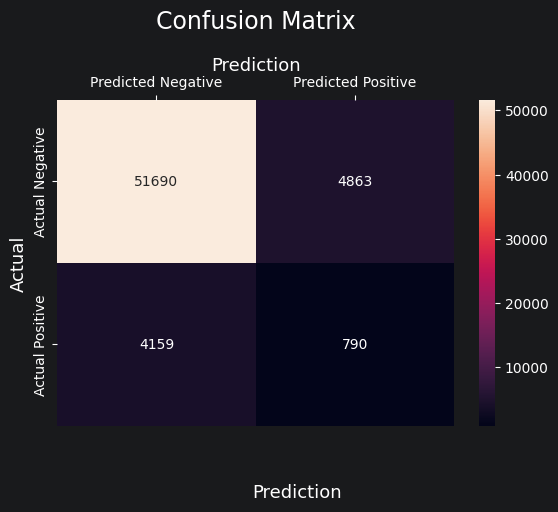

In [43]:
sns.heatmap(cm,
            annot=True,
            fmt='g',
            xticklabels=['Predicted Negative','Predicted Positive'],
            yticklabels=['Actual Negative','Actual Positive'])
plt.ylabel('Actual', fontsize=13)
plt.title('Confusion Matrix', fontsize=17, pad=20)
plt.gca().xaxis.set_label_position('top')
plt.xlabel('Prediction', fontsize=13)
plt.gca().xaxis.tick_top()

plt.gca().figure.subplots_adjust(bottom=0.2)
plt.gca().figure.text(0.5, 0.05, 'Prediction', ha='center', fontsize=13)
plt.show()

Класифікуємо дані з файлу application_test.csv та запишемо результат у submission.csv

In [44]:
test_data = pd.read_csv('lab2/application_test.csv')
print(test_data.shape)
test_data.head()

(48744, 121)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [45]:
test_data.isnull().sum().sort_values(ascending=False)

COMMONAREA_AVG              33495
COMMONAREA_MEDI             33495
COMMONAREA_MODE             33495
NONLIVINGAPARTMENTS_AVG     33347
NONLIVINGAPARTMENTS_MEDI    33347
                            ...  
FLAG_DOCUMENT_16                0
FLAG_DOCUMENT_15                0
FLAG_DOCUMENT_14                0
FLAG_DOCUMENT_20                0
FLAG_DOCUMENT_21                0
Length: 121, dtype: int64

In [46]:
sorted_test_data = test_data[sorted_features.columns]

In [47]:
sorted_test_data[num_col_to_fill] = sorted_test_data[num_col_to_fill].fillna(train_mean)

In [48]:
sorted_test_data['NAME_TYPE_SUITE'] = sorted_test_data['NAME_TYPE_SUITE'].fillna(NAME_TYPE_SUITE_mode)

sorted_test_data['OCCUPATION_TYPE'] = sorted_test_data['OCCUPATION_TYPE'].fillna(OCCUPATION_TYPE_mode)


In [49]:
encoded_test_data = encoder.transform(sorted_test_data[categorical_columns])
encoded_test_df = pd.DataFrame(
    encoded_test_data,
    columns=encoder.get_feature_names_out(categorical_columns),
    index = sorted_test_data.index
)
final_test_df = pd.concat(
    [sorted_test_data.drop(columns=categorical_columns), encoded_test_df],
    axis=1
)

In [50]:
y_pred_test = clf.predict(final_test_df)

In [51]:
y_pred_test.shape

(48744,)

In [52]:
test_result = pd.DataFrame(y_pred_test, columns = ['TARGET'])

In [53]:
ids = test_data['SK_ID_CURR']

In [54]:
ids.head(5)

0    100001
1    100005
2    100013
3    100028
4    100038
Name: SK_ID_CURR, dtype: int64

In [55]:
res = pd.concat([ids, test_result], axis=1)

In [56]:
res.to_csv('submission.csv', index=False)

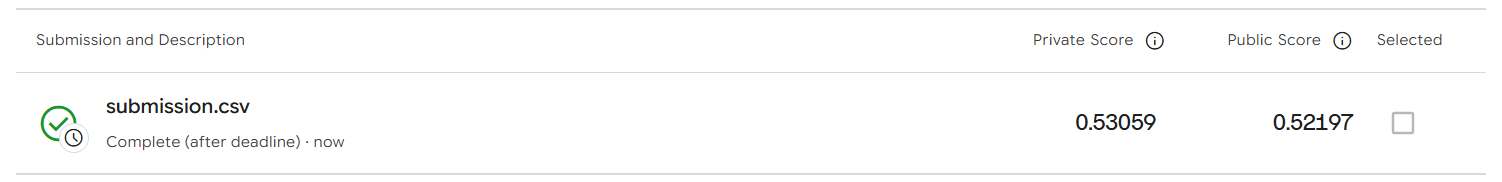